# NHS England A&E | M03 - From data-quality evidence to preprocessing decisions
**ICA2 · Intelligent Decision Support Systems**  
**Research scope:** provider-month Type 1 attendance forecasting, January 2022–September 2026.

## Aim and approach
Can we use the historical monthly returns as a reliable starting point for forecasting? We examine completeness, provider identity, numeric validity, aggregate reconciliation and patterns over time. Each section follows **question → method → result → interpretation → next decision**.

- Input: M02 combined CSV/Parquet in `data/staging/`, from the [project repository](https://github.com/neoscar10/NHS-A-E-IDSS). Original files are retained in `data/raw/`.
- Source publication: [NHS England A&E Attendances and Emergency Admissions](https://www.england.nhs.uk/statistics/statistical-work-areas/ae-waiting-times-and-activity/).
- Grain: one reporting organisation per month, plus separate national TOTAL rows in the staging file. Counts are monthly, not patient-level or daily.
- M03 only audits data; it does not impute values, remove providers or fit models. The charts and conclusions update when the notebook runs. A missing record must not be interpreted as zero demand.

**Run instructions:** Open the cloned repository in VS Code, select your project Python kernel and run all cells in order. The existing `m03_validate.py` remains the authoritative validator.

**Evidence collection:** Each execution creates a new timestamped M03 folder. The existing validator is rerun against the staged input, with new reports written inside the evidence folder. Existing M03 reports and raw/staged files are not overwritten. Figures are saved as 300 DPI PNG files; tests are rerun on synthetic fixtures.

## 1. Setup and reusable presentation style
Import the existing validator. We use pandas for summaries and Matplotlib for charts; Markdown outputs translate each calculated result into a decision.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter, MaxNLocator

candidates = [Path.cwd(), *Path.cwd().parents]
repo_root = next((p for p in candidates if (p / "src/data/m03_validate.py").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Open the NHS-A-E-IDSS folder in VS Code, then run this notebook with its Conda kernel.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from src.data.m03_validate import validate_dataset
print("Repository:", repo_root)
print("Notebook kernel Python:", sys.executable)

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
BLUE, TEAL, AMBER, GREY = "#245A81", "#167C80", "#B56B13", "#687784"

def note(text):
    display(Markdown(text))

def time_axis(ax):
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=11))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=.22)

def heading(ax, title, subtitle):
    ax.set_title(title, loc="left", pad=30, fontsize=13)
    ax.text(0, 1.025, subtitle, transform=ax.transAxes, fontsize=9, color=GREY, va="bottom")

from src.utils.evidence_exporter import EvidenceRun, record_common_inputs
RUN_TESTS = True
evidence = EvidenceRun(repo_root, "M03", "Re-run unchanged M03 validator and archive research evidence.")
record_common_inputs(evidence, include_staged=True)
evidence.record_input("src/data/m03_validate.py")
print("Evidence folder:", evidence.path.relative_to(repo_root))

Repository: c:\Users\hp\NHS-A-E-IDSS
Notebook kernel Python: c:\Users\hp\anaconda3\python.exe
Evidence folder: docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660


## 2. Validation at a glance
**Question:** Is the staged input internally consistent enough to proceed to documented standardisation?

The validator checks source provenance, provider-month uniqueness, 18 count measures and national totals. A `PASS_CORE_CHECKS_WITH_ADVISORIES` result means implemented blocking checks passed, not that all providers are suitable for forecasting.

In [2]:
result = validate_dataset(repo_root, output_root=evidence.path / "reports")
summary = result["summary"]
checks = summary["checks"]
monthly = result["monthly"].sort_values("source_month").copy()
issues = result["findings"].copy()
recon = result["reconciliation"].copy()
continuity = result["continuity"].copy()
changes = result["change_candidates"].copy()

note(f"### Run result: `{summary['quality_gate']}`\n"
     f"**{summary['input_rows']:,} records · {summary['provider_rows']:,} provider rows · "
     f"{summary['aggregate_rows']:,} national rows · {summary['observed_months']} months**\n\n"
     f"Period: {summary['first_month']} to {summary['last_month']}. Input: `{summary['source_input']}`.")
display(pd.DataFrame([
    ("Core error groups", checks["error_groups"]),
    ("Warning groups", checks["warning_groups"]),
    ("National comparisons matched", checks["reconciliations_matched"]),
    ("Providers with internal gaps", checks["providers_with_internal_month_gaps"]),
    ("Provider codes with name variants", checks["providers_with_name_variants"]),
    ("Large Type 1 change candidates", checks["type1_change_review_candidates"]),
    ("M01 manifest cross-check", checks["m01_manifest_check"]),
    ("M01 month coverage cross-check", checks["m01_month_coverage_check"]),
    ("M02 row-count cross-check", checks["m02_row_count_check"]),
], columns=["Quality indicator", "Observed result"]))
if checks["error_groups"]:
    note("**Decision:** Investigate core errors before accepting a cleaned modelling input.")
else:
    note("**Decision:** Proceed to documented standardisation, while investigating longitudinal advisories and any unavailable provenance checks.")

### Run result: `PASS_CORE_CHECKS_WITH_ADVISORIES`
**11,449 records · 11,392 provider rows · 57 national rows · 57 months**

Period: 2022-01 to 2026-09. Input: `data/staging/ae_historical_raw_combined.parquet`.

,Quality indicator,Observed result
0,Core error groups,0
1,Warning groups,0
2,National comparisons matched,1026
3,Providers with internal gaps,12
4,Provider codes with name variants,18
5,Large Type 1 change candidates,0
6,M01 manifest cross-check,MATCH
7,M01 month coverage cross-check,MATCH
8,M02 row-count cross-check,MATCH


**Decision:** Proceed to documented standardisation, while investigating longitudinal advisories and any unavailable provenance checks.

### 2.1 What was flagged?
Errors are blocking core issues. Warnings are contextual review prompts. An affected row may occur in multiple check groups; counts must not be interpreted as unique affected records. Continuity and change candidates are reported separately.

In [3]:
if issues.empty:
    note("No grouped row-level errors or warnings were returned by the validator. Continuity and changes still require separate review.")
else:
    display(issues.sort_values(["severity", "affected_rows"], ascending=[True, False]).head(20))
    note("**Next decision:** Trace each flagged check to its source record before any correction. Do not delete a row simply because it was flagged.")

No grouped row-level errors or warnings were returned by the validator. Continuity and changes still require separate review.

## 3. Does the reporting population remain stable?
**Method:** Count provider records per reporting month, excluding national TOTAL rows. This assesses reporting coverage, not the number of physical hospitals or emergency departments. One organisation may cover several sites.

**Why it matters:** A national time series can have complete monthly coverage while individual providers enter, exit or have missing observations.

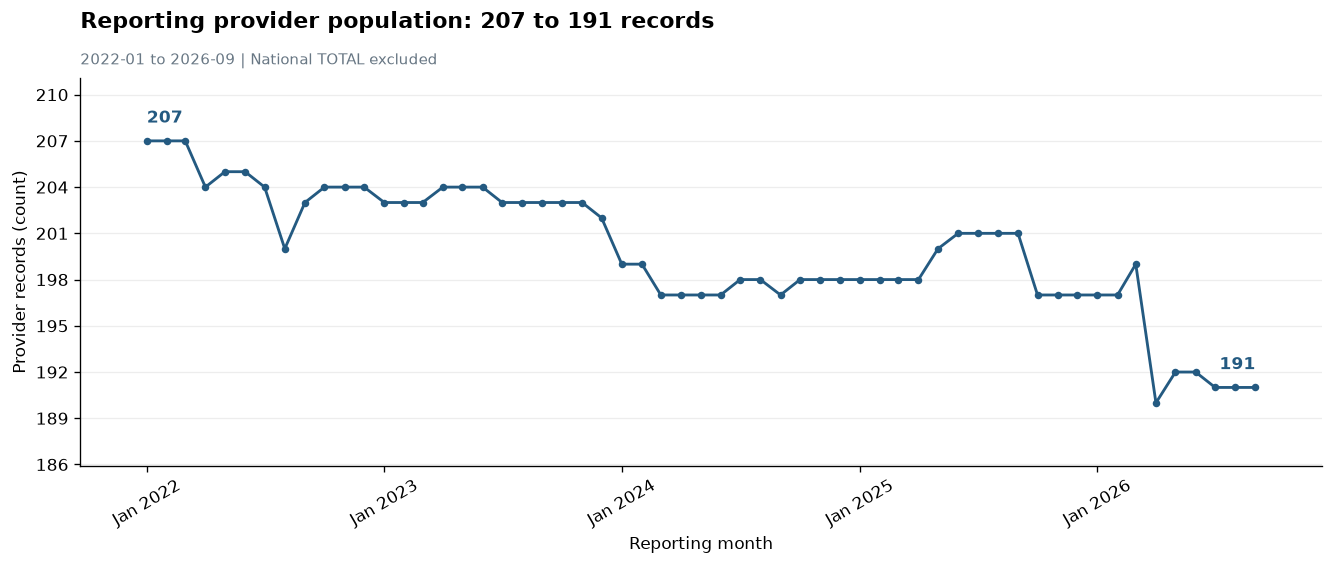

**Observed:** 207 provider records in 2022-01 and 191 in 2026-09 (net change -16). The minimum is 190 in 2026-04. These counts are not verified physical site counts.

**Interpretation:** Changes can reflect reporting coverage or real organisational changes; the graph cannot establish the cause.

**M05 decision:** Treat the dataset as potentially unbalanced. Audit provider histories and build calendar-aligned lags; never let a row-based lag silently jump across an absent month.

In [4]:
dates = pd.to_datetime(monthly["source_month"], format="%Y-%m")
counts = monthly["provider_rows"]
first, last = int(counts.iloc[0]), int(counts.iloc[-1])
min_i = counts.idxmin()
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
ax.plot(dates, counts, color=BLUE, marker="o", markersize=3.5, linewidth=1.7)
heading(ax, f"Reporting provider population: {first:,} to {last:,} records",
        f"{monthly.source_month.iloc[0]} to {monthly.source_month.iloc[-1]} | National TOTAL excluded")
ax.set(xlabel="Reporting month", ylabel="Provider records (count)")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
time_axis(ax)
ax.margins(x=.06, y=.24)
for idx, align in [(counts.index[0], "left"), (counts.index[-1], "right")]:
    ax.annotate(f"{int(counts.loc[idx])}", (dates.loc[idx], counts.loc[idx]),
                xytext=(0, 11), textcoords="offset points", ha=align, color=BLUE, fontweight="bold")
evidence.save_figure(fig, "01_provider_population.png")
plt.show()
note(f"**Observed:** {first:,} provider records in {monthly.source_month.iloc[0]} and {last:,} in "
     f"{monthly.source_month.iloc[-1]} (net change {last-first:+,}). The minimum is {int(counts.loc[min_i]):,} in "
     f"{monthly.loc[min_i, 'source_month']}. These counts are not verified physical site counts.\n\n"
     "**Interpretation:** Changes can reflect reporting coverage or real organisational changes; the graph cannot establish the cause.\n\n"
     "**M05 decision:** Treat the dataset as potentially unbalanced. Audit provider histories and build calendar-aligned lags; never let a row-based lag silently jump across an absent month.")

## 4. How relevant is the dataset to Type 1 forecasting?
**Method:** Divide the number of provider records with a valid, recorded Type 1 zero by all provider records in each month. This is a share of records, not of patients. Missing or invalid values are not counted as zero; interpret alongside core validation.

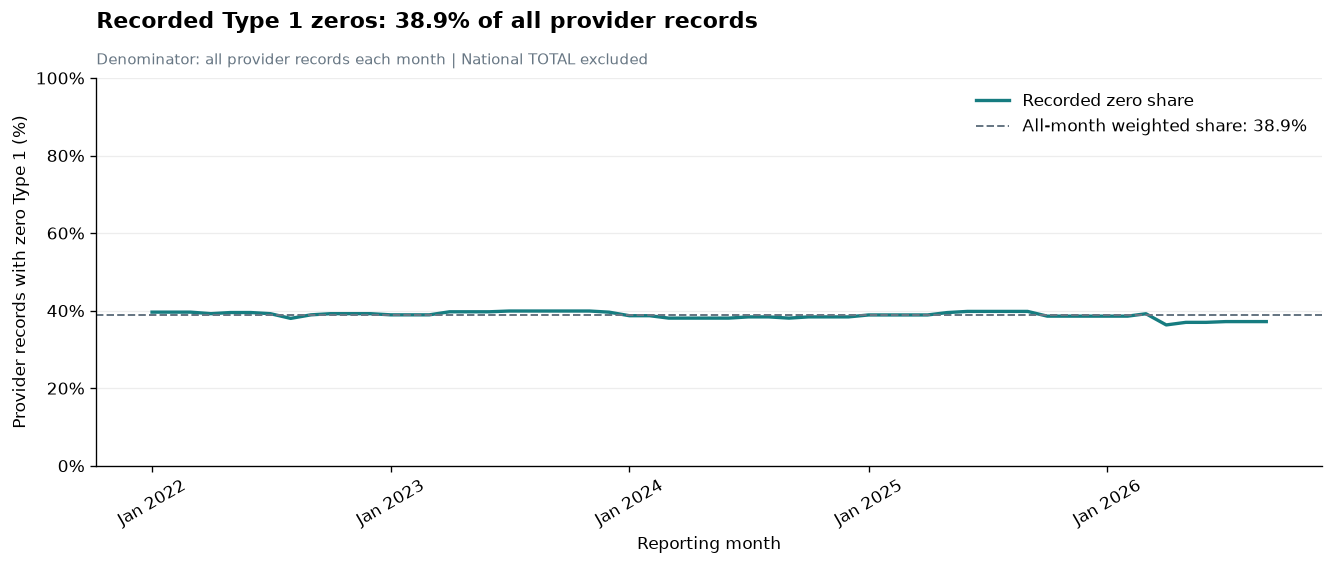

**Observed:** 4,426 of 11,392 provider records have a recorded Type 1 zero (38.9% overall). Monthly shares range from 36.3% to 39.9%.

**Interpretation:** Some reporting organisations may not provide Type 1 services. A zero alone does not establish service eligibility.

**M04 decision:** Preserve valid zeros and keep missing counts distinct. **M05/modelling decision:** Define Type 1 eligibility from service metadata or attendance history available at the forecast origin; do not use future activity to select training or test providers.

In [5]:
zero_total = int(monthly["type1_zero_provider_rows"].sum())
share = monthly["type1_zero_provider_share"] * 100
weighted_share = 100 * zero_total / summary["provider_rows"] if summary["provider_rows"] else float("nan")
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
ax.plot(dates, share, color=TEAL, linewidth=2, label="Recorded zero share")
ax.axhline(weighted_share, color=GREY, linestyle="--", linewidth=1.2,
           label=f"All-month weighted share: {weighted_share:.1f}%")
heading(ax, f"Recorded Type 1 zeros: {weighted_share:.1f}% of all provider records",
        "Denominator: all provider records each month | National TOTAL excluded")
ax.set(xlabel="Reporting month", ylabel="Provider records with zero Type 1 (%)", ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
time_axis(ax)
ax.legend(loc="upper right", frameon=False)
evidence.save_figure(fig, "02_type1_zero_share.png")
plt.show()
note(f"**Observed:** {zero_total:,} of {summary['provider_rows']:,} provider records have a recorded Type 1 zero "
     f"({weighted_share:.1f}% overall). Monthly shares range from {share.min():.1f}% to {share.max():.1f}%.\n\n"
     "**Interpretation:** Some reporting organisations may not provide Type 1 services. A zero alone does not establish service eligibility.\n\n"
     "**M04 decision:** Preserve valid zeros and keep missing counts distinct. **M05/modelling decision:** Define Type 1 eligibility from service metadata or attendance history available at the forecast origin; do not use future activity to select training or test providers.")

## 5. Do the provider figures reconcile to the published national totals?
**Method:** For each reporting month and each published count measure, compare the sum of provider records with the national TOTAL value. `NOT_COMPARABLE` means a malformed count or absent/non-unique total prevents comparison. A match checks additivity, not independent accuracy of reporting.

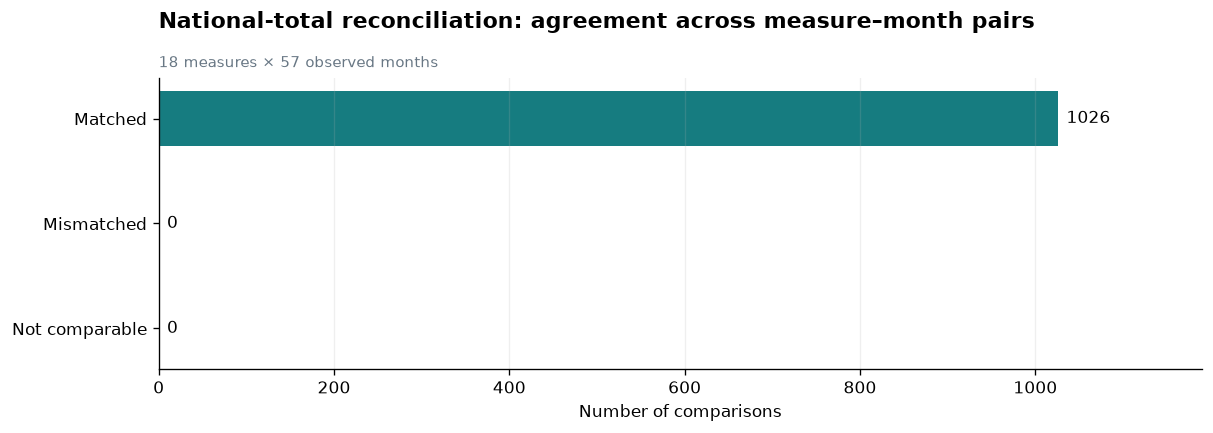

**Observed:** 1,026 of 1,026 comparisons matched; 0 mismatched and 0 were not comparable.

**M04 decision:** Preserve national TOTAL rows in a separate reference table and exclude them from the provider-level analytical table to prevent double counting.

In [6]:
status_order = ["MATCH", "MISMATCH", "NOT_COMPARABLE"]
status_counts = recon["status"].value_counts().reindex(status_order, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
bars = ax.barh(["Matched", "Mismatched", "Not comparable"], status_counts.values,
               color=[TEAL, AMBER, GREY], height=.52)
ax.invert_yaxis()
ax.bar_label(bars, padding=5, fmt="%d")
ax.set_xlim(0, max(1, status_counts.max()) * 1.16)
heading(ax, "National-total reconciliation: agreement across measure–month pairs",
        f"{summary['expected_measure_columns']} measures × {summary['observed_months']} observed months")
ax.set_xlabel("Number of comparisons")
ax.grid(axis="x", alpha=.2)
evidence.save_figure(fig, "03_national_reconciliation.png")
plt.show()
problems = recon[recon["status"] != "MATCH"]
if not problems.empty:
    display(problems.head(20))
note(f"**Observed:** {status_counts['MATCH']:,} of {len(recon):,} comparisons matched; "
     f"{status_counts['MISMATCH']:,} mismatched and {status_counts['NOT_COMPARABLE']:,} were not comparable.\n\n"
     + ("**Decision:** Investigate non-matches before accepting the data; do not silently replace published values." if len(problems) else
        "**M04 decision:** Preserve national TOTAL rows in a separate reference table and exclude them from the provider-level analytical table to prevent double counting."))

## 6. Which providers have gaps or naming inconsistencies?
**Method:** For each normalised organisation code, count observed months and missing months between the first and last recorded months. Count distinct normalised names. Gaps outside the observed span are not labelled internal gaps. Name variants are not proof of mergers or changes in provider identity.

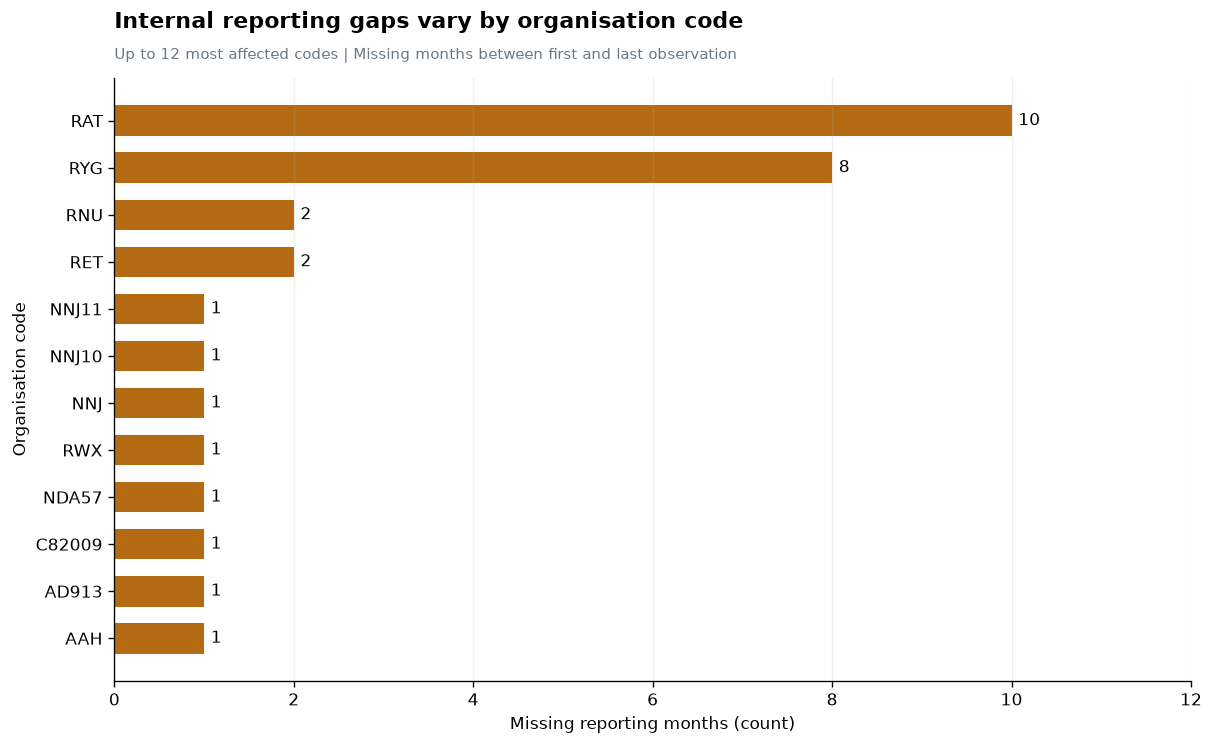

,org_code,first_month,last_month,observed_months,missing_within_span,missing_months_example,zero_type1_observations,nonzero_type1_observations
73,RAT,2022-01,2026-09,47,10,2024-03 | 2024-04 | 2024-05 | 2024-06 | 2024-0...,47,0
206,RYG,2022-01,2026-09,49,8,2022-08 | 2022-09 | 2022-10 | 2022-11 | 2022-1...,49,0
144,RNU,2022-01,2026-09,55,2,2022-08 | 2022-09,55,0
99,RET,2022-01,2026-09,55,2,2024-01 | 2024-09,55,0
24,NDA57,2022-01,2023-12,23,1,2022-07,23,0
11,C82009,2022-01,2026-09,56,1,2025-05,56,0
5,AD913,2022-01,2026-09,56,1,2022-08,56,0
2,AAH,2022-01,2026-09,56,1,2022-04,56,0
38,NNJ11,2026-03,2026-09,6,1,2026-04,6,0
37,NNJ10,2026-03,2026-09,6,1,2026-04,6,0


**Observed:** 12 of 223 organisation codes have internal gaps; 18 have more than one recorded name.

**M04 decision:** Standardise identifier whitespace and casing, retaining source names. **M05 decision:** Investigate code history and missing periods before linking organisations or constructing lags. Do not automatically fill a missing month with zero.

,org_code,first_month,last_month,distinct_provider_names,nonzero_type1_observations
1,A5D4Q,2025-03,2025-09,2,0
42,NNJ15,2022-01,2026-09,2,0
63,RA2,2022-01,2026-09,2,57
65,RA7,2022-01,2026-09,2,57
74,RAX,2022-01,2026-09,2,57
78,RBN,2022-01,2026-09,2,57
109,RH8,2022-01,2026-09,2,57
112,RHU,2022-01,2026-09,2,57
119,RJC,2022-01,2026-09,2,57
153,RQX,2022-01,2026-09,2,57


In [7]:
gap_providers = continuity[continuity["missing_within_span"] > 0].sort_values("missing_within_span", ascending=False)
name_providers = continuity[continuity["name_change_flag"]]
if gap_providers.empty:
    note("No internal provider-month gaps detected by this check.")
else:
    top = gap_providers.head(12).sort_values("missing_within_span")
    fig, ax = plt.subplots(figsize=(10, max(3.4, .35 * len(top) + 1.9)), layout="constrained")
    bars = ax.barh(top["org_code"], top["missing_within_span"], color=AMBER, height=.65)
    ax.bar_label(bars, padding=4, fmt="%d")
    ax.set_xlim(0, max(1, top["missing_within_span"].max()) * 1.2)
    heading(ax, "Internal reporting gaps vary by organisation code",
            "Up to 12 most affected codes | Missing months between first and last observation")
    ax.set(xlabel="Missing reporting months (count)", ylabel="Organisation code")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="x", alpha=.2)
    evidence.save_figure(fig, "04_provider_reporting_gaps.png")
    plt.show()
    display(gap_providers[["org_code", "first_month", "last_month", "observed_months", "missing_within_span", "missing_months_example", "zero_type1_observations", "nonzero_type1_observations"]].head(12))
note(f"**Observed:** {len(gap_providers):,} of {len(continuity):,} organisation codes have internal gaps; "
     f"{len(name_providers):,} have more than one recorded name.\n\n"
     "**M04 decision:** Standardise identifier whitespace and casing, retaining source names. **M05 decision:** Investigate code history and missing periods before linking organisations or constructing lags. Do not automatically fill a missing month with zero.")
if not name_providers.empty:
    display(name_providers[["org_code", "first_month", "last_month", "distinct_provider_names", "nonzero_type1_observations"]].head(12))

### 6.1 Distinguish observed activity from service eligibility
Classify each code descriptively using the entire audited history. These groups are **retrospective summaries only**, not the model cohort. They must not be used to select earlier training or testing records using future information.

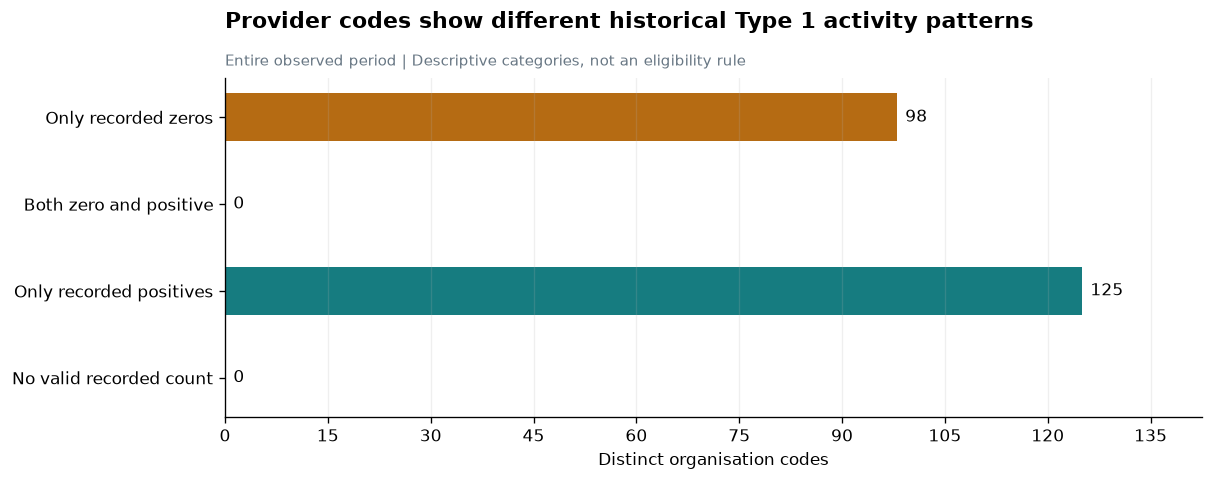

**Observed:** 98 codes have only recorded zeros; 0 have both zero and positive activity; 125 have only recorded positives. Invalid counts are excluded from this classification.

**Next decision:** Investigate persistent zero activity and service transitions; define a forecast-origin cohort without using future values.

In [8]:
zero = continuity["zero_type1_observations"]
positive = continuity["nonzero_type1_observations"]
# If invalid or duplicate rows exist, the comparison is provisional.
activity = pd.Series({"Only recorded zeros": int(((zero > 0) & (positive == 0)).sum()),
                      "Both zero and positive": int(((zero > 0) & (positive > 0)).sum()),
                      "Only recorded positives": int(((zero == 0) & (positive > 0)).sum()),
                      "No valid recorded count": int(((zero == 0) & (positive == 0)).sum())})
fig, ax = plt.subplots(figsize=(10, 3.9), layout="constrained")
bars = ax.barh(activity.index, activity.values, color=[AMBER, GREY, TEAL, GREY], height=.55)
ax.invert_yaxis()
ax.bar_label(bars, padding=5, fmt="%d")
ax.set_xlim(0, max(1, activity.max()) * 1.14)
heading(ax, "Provider codes show different historical Type 1 activity patterns",
        "Entire observed period | Descriptive categories, not an eligibility rule")
ax.set_xlabel("Distinct organisation codes")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", alpha=.2)
evidence.save_figure(fig, "05_type1_activity_patterns.png")
plt.show()
note(f"**Observed:** {activity.iloc[0]:,} codes have only recorded zeros; {activity.iloc[1]:,} have both zero and positive activity; "
     f"{activity.iloc[2]:,} have only recorded positives. Invalid counts are excluded from this classification.\n\n"
     "**Next decision:** Investigate persistent zero activity and service transitions; define a forecast-origin cohort without using future values.")

## 7. Are there abrupt Type 1 demand changes to investigate?
The existing validator flags consecutive-month changes only when both the absolute change is at least 2,000 attendances and the absolute relative change is at least 100%, with a positive previous count. This rule is a heuristic, not a statistical outlier test. It does not detect zero-to-positive transitions or changes across gaps, and under this relative threshold declines smaller than 100% are not flagged.

In [9]:
if changes.empty:
    note("**Observed:** No candidates met this particular rule. This is not proof that all changes are normal.")
else:
    ranked = changes.assign(magnitude=changes["absolute_change"].abs()).sort_values("magnitude", ascending=False)
    display(ranked.drop(columns="magnitude").head(12))
    note(f"**Observed:** {len(changes):,} provider-month transitions met the configured screening rule.")
note("**M05 decision:** Inspect the source file, provider history and possible service changes for each candidate. Retain plausible actual demand spikes rather than automatically clipping or deleting them; review alternative change screens if needed.")

**Observed:** No candidates met this particular rule. This is not proof that all changes are normal.

**M05 decision:** Inspect the source file, provider history and possible service changes for each candidate. Retain plausible actual demand spikes rather than automatically clipping or deleting them; review alternative change screens if needed.

## 8. Decision register - handover to preprocessing
The following table combines measured evidence from the current run with proposed actions. M04 transforms the data; M05 handles longitudinal comparability and forecasting eligibility. Neither action is executed here.

In [10]:
actions = pd.DataFrame([
    ("Core validity / provenance", f"{checks['error_groups']} error groups; manifest {checks['m01_manifest_check']}", "Resolve errors or unavailable checks before accepting a cleaned input", "M04"),
    ("National aggregate rows", f"{summary['aggregate_rows']} total rows; {status_counts['MATCH']} matches", "Keep a separate national table; exclude TOTAL from provider modelling", "M04"),
    ("Dates and types", f"{summary['observed_months']} months; {summary['expected_measure_columns']} count measures", "Standardise month dates, headers, textual IDs and integer counts; preserve lineage", "M04"),
    ("Recorded zeros", f"{weighted_share:.1f}% of provider records", "Keep zeros distinct from missing; define eligibility at forecast origin", "M04/M05"),
    ("Provider reporting gaps", f"{len(gap_providers)} codes with internal gaps", "Investigate gaps and align features to calendar months", "M05"),
    ("Provider identity", f"{len(name_providers)} codes with name variants", "Verify name/code changes before combining histories", "M05"),
    ("Demand change candidates", f"{len(changes)} transitions flagged", "Investigate source/context; do not treat flags as errors", "M05"),
], columns=["Evidence area", "Measured result", "Proposed next decision", "Milestone"])
with pd.option_context("display.max_colwidth", None):
    display(actions)
note("**Overall conclusion:** " + ("Resolve core errors before accepting M04 output." if checks["error_groups"] else "Implemented core checks passed. Standardisation can proceed with the listed advisories retained for review.") +
     " This does not establish forecasting accuracy, clinical suitability or independent verification of the published data.")
evidence.write_table("reports/m03_preprocessing_decisions.csv", actions)


,Evidence area,Measured result,Proposed next decision,Milestone
0,Core validity / provenance,0 error groups; manifest MATCH,Resolve errors or unavailable checks before accepting a cleaned input,M04
1,National aggregate rows,57 total rows; 1026 matches,Keep a separate national table; exclude TOTAL from provider modelling,M04
2,Dates and types,57 months; 18 count measures,"Standardise month dates, headers, textual IDs and integer counts; preserve lineage",M04
3,Recorded zeros,38.9% of provider records,Keep zeros distinct from missing; define eligibility at forecast origin,M04/M05
4,Provider reporting gaps,12 codes with internal gaps,Investigate gaps and align features to calendar months,M05
5,Provider identity,18 codes with name variants,Verify name/code changes before combining histories,M05
6,Demand change candidates,0 transitions flagged,Investigate source/context; do not treat flags as errors,M05


**Overall conclusion:** Implemented core checks passed. Standardisation can proceed with the listed advisories retained for review. This does not establish forecasting accuracy, clinical suitability or independent verification of the published data.

WindowsPath('C:/Users/hp/NHS-A-E-IDSS/docs/evidence/M03_Data_Quality/20261117T231855Z_f674a660/reports/m03_preprocessing_decisions.csv')

## 9. Preserve evidence and review the run
The unchanged validator has written its reports below this run's `reports/` folder. PNGs and the decision register are saved automatically. Test results describe fresh synthetic-fixture tests, not model accuracy. Save the executed notebook with Ctrl+S. If a run is interrupted, its manifest remains `IN_PROGRESS`; run all cells again to create a separate snapshot.

In [11]:
print("M03 quality gate:", summary["quality_gate"])
print("Generated files:")
for name, path in result["outputs"].items():
    print(f"  {name:15s} {Path(path).relative_to(repo_root)}")
if RUN_TESTS:
    rc = evidence.run_tests("tests/test_m03_validate.py")
    print("M03 pytest exit code:", rc)
path = evidence.finish(
    "Fresh M03 validation using the staged input. No preprocessing or forecasting performed.",
    review_required=summary["quality_gate"] == "REVIEW_REQUIRED")
print("Evidence saved:", path.relative_to(repo_root))
print("Evidence status:", json.loads((path / "evidence_manifest.json").read_text(encoding="utf-8"))["status"])

M03 quality gate: PASS_CORE_CHECKS_WITH_ADVISORIES
Generated files:
  summary         docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660\reports\docs\m03_quality_summary.json
  report          docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660\reports\docs\m03_quality_report.md
  findings        docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660\reports\data\quality\m03_findings.csv
  monthly         docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660\reports\docs\m03_monthly_profile.csv
  reconciliation  docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660\reports\docs\m03_monthly_reconciliation.csv
  continuity      docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660\reports\docs\m03_provider_continuity.csv
  changes         docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660\reports\docs\m03_type1_change_candidates.csv
M03 pytest exit code: 0
Evidence saved: docs\evidence\M03_Data_Quality\20261117T231855Z_f674a660
Evidence status: COMPLETE
